Check first if the GPU works

In [3]:
!nvidia-smi
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    x = torch.randn(1000, 1000, device="cuda")
    print("Test matmul OK:", (x @ x).shape)

Thu Nov 19 11:51:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Load the dataset

In [4]:
from datasets import load_dataset

REPO = "chehablab/NCT-CRC-HE-100K"
test_full = load_dataset(REPO, split="test")

print(test_full)
print(test_full.features)
row = test_full[0]
print({k: (type(v), v if not hasattr(v, "size") else v.size) for k, v in row.items()})

README.md:   0%|          | 0.00/8.11k [00:00<?, ?B/s]

data/train-00000-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  484MB            

data/train-00000-of-00013.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  313MB            

data/train-00001-of-00013.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  386MB            

... (22 outputs left out)

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/100000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7180 [00:00<?, ? examples/s]

Dataset({
    features: ['patch_id', 'image', 'tissue', 'label'],
    num_rows: 7180
})
{'patch_id': Value('string'), 'image': Image(mode=None, decode=True), 'tissue': Value('string'), 'label': Value('int32')}
{'patch_id': (<class 'str'>, 'ADI-TCGA-AAICEQFN'), 'image': (<class 'PIL.PngImagePlugin.PngImageFile'>, (224, 224)), 'tissue': (<class 'str'>, 'ADI'), 'label': (<class 'int'>, 0)}


Data Pipeline

In [5]:
from datasets import load_dataset

REPO = "chehablab/NCT-CRC-HE-100K"
SEED = 42
N_SUBSET = 20000   # we can raise this later

test_full  = load_dataset(REPO, split="test")      # external test set
train_full = load_dataset(REPO, split="train")

subset = train_full.shuffle(seed=SEED).select(range(N_SUBSET))

split = subset.train_test_split(test_size=0.30, seed=SEED, shuffle=True)
train_ds, heldout = split["train"], split["test"]

halves = heldout.train_test_split(test_size=0.50, seed=SEED, shuffle=True)
calib_ds, internal_test_ds = halves["train"], halves["test"]

print("train:", len(train_ds))
print("calibration:", len(calib_ds))
print("internal test:", len(internal_test_ds))
print("external test:", len(test_full))
print(train_ds.features)

train: 14000
calibration: 3000
internal test: 3000
external test: 7180
{'patch_id': Value('string'), 'image': Image(mode=None, decode=True), 'tissue': Value('string'), 'label': Value('int32')}


In [6]:
import os, torch, torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import transforms as T
from datasets import Image as HFImage, ClassLabel

DEVICE = "cuda"
feats = train_ds.features

# --- find the image and label columns ---
IMG_COL = next(k for k, v in feats.items() if isinstance(v, HFImage))
if "label" in feats:
    LBL_COL = "label"
else:
    LBL_COL = next(k for k, v in feats.items()
                   if isinstance(v, ClassLabel) or getattr(v, "dtype", "") in ("int64", "int32", "string"))
print("image column:", IMG_COL, "| label column:", LBL_COL)

# --- turn labels into 0..8 and get class names ---
lf = feats[LBL_COL]
if isinstance(lf, ClassLabel):
    CLASSES = list(lf.names)
    to_idx = int
elif getattr(lf, "dtype", "") == "string":
    CLASSES = sorted(set(train_ds[LBL_COL]))
    _m = {c: i for i, c in enumerate(CLASSES)}
    to_idx = lambda v: _m[v]
else:
    _ids = sorted(set(int(v) for v in train_ds[LBL_COL]))
    CLASSES = [str(i) for i in _ids]
    to_idx = lambda v: _ids.index(int(v))
print("classes:", CLASSES)
assert len(CLASSES) == 9, "expected 9 classes, paste me the output above"

# --- transforms: flips/rotations for training only ---
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomApply([T.RandomRotation((90, 90))], p=0.5),
    T.ToTensor(), T.Normalize(MEAN, STD)])
eval_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(MEAN, STD)])

def make(ds, tf):
    def fn(batch):
        return {"x": [tf(im.convert("RGB")) for im in batch[IMG_COL]],
                "y": [to_idx(l) for l in batch[LBL_COL]]}
    return ds.with_transform(fn)

NW = min(4, os.cpu_count() or 2)
def loader(ds, tf, shuffle):
    return DataLoader(make(ds, tf), batch_size=64, shuffle=shuffle, num_workers=NW,
                      pin_memory=True, persistent_workers=True)

train_dl    = loader(train_ds, train_tf, shuffle=True)    # reshuffled every epoch
calib_dl    = loader(calib_ds, eval_tf, shuffle=False)
internal_dl = loader(internal_test_ds, eval_tf, shuffle=False)
external_dl = loader(test_full, eval_tf, shuffle=False)

b = next(iter(train_dl))
print("batch:", b["x"].shape, b["y"][:10])

image column: image | label column: label
classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8']
batch: torch.Size([64, 3, 224, 224]) tensor([1, 6, 6, 0, 6, 3, 3, 8, 8, 3])


Fine Tuning

In [7]:
import time, timm

model = timm.create_model("resnet18", pretrained=True, num_classes=len(CLASSES)).to(DEVICE)

EPOCHS, MAX_LR = 5, 5e-4
opt = torch.optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=MAX_LR, total_steps=EPOCHS * len(train_dl))
scaler = torch.amp.GradScaler("cuda")

@torch.no_grad()
def get_logits(model, dl):
    model.eval(); L, Y = [], []
    for b in dl:
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(b["x"].to(DEVICE, non_blocking=True))
        L.append(out.float().cpu()); Y.append(b["y"])
    return torch.cat(L), torch.cat(Y)

for ep in range(EPOCHS):
    model.train(); t0 = time.time(); run_loss = 0.0
    for b in train_dl:
        x, y = b["x"].to(DEVICE, non_blocking=True), b["y"].to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = F.cross_entropy(model(x), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update(); sched.step()
        run_loss += loss.item()
    lg, yy = get_logits(model, calib_dl)
    acc = (lg.argmax(1) == yy).float().mean().item()
    print(f"epoch {ep+1}/{EPOCHS}  loss {run_loss/len(train_dl):.3f}  calib acc {acc:.3f}  ({time.time()-t0:.0f}s)")

torch.save(model.state_dict(), "resnet18_finetuned.pt")
print("saved resnet18_finetuned.pt")

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 1/5  loss 1.350  calib acc 0.922  (75s)
epoch 2/5  loss 0.171  calib acc 0.970  (58s)
epoch 3/5  loss 0.094  calib acc 0.983  (58s)
epoch 4/5  loss 0.063  calib acc 0.988  (60s)
epoch 5/5  loss 0.048  calib acc 0.988  (56s)
saved resnet18_finetuned.pt


Testing with real world data

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


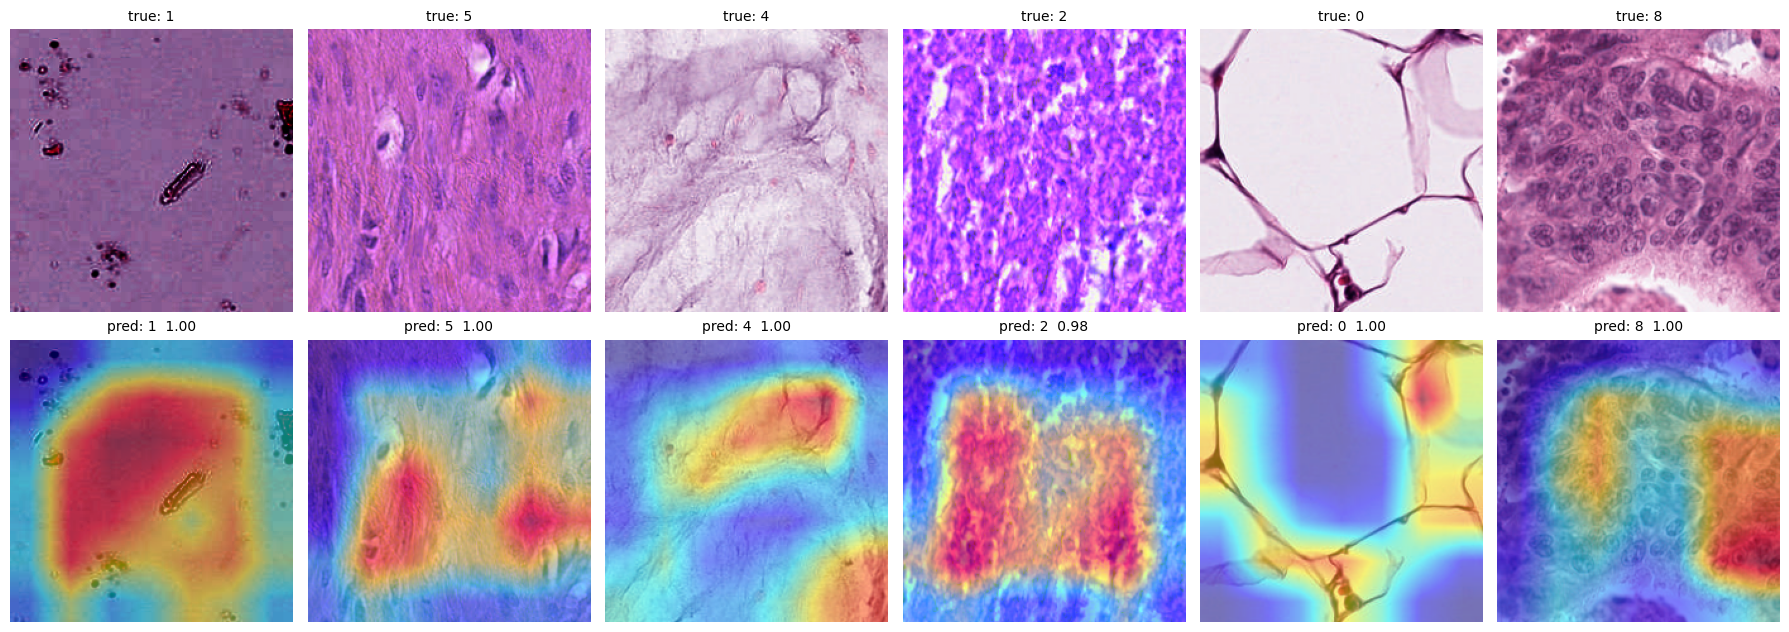

In [9]:
!pip install -q datasets timm grad-cam scikit-learn
import numpy as np, matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

model.eval()
cam = GradCAM(model=model, target_layers=[model.layer4[-1]])   # last conv block of ResNet18

rng = np.random.default_rng(0)
idxs = rng.choice(len(test_full), 6, replace=False)
xs, ys = [], []
for i in idxs:
    r = test_full[int(i)]
    xs.append(eval_tf(r[IMG_COL].convert("RGB")))
    ys.append(to_idx(r[LBL_COL]))
x = torch.stack(xs).to(DEVICE)

with torch.no_grad():
    probs = torch.softmax(model(x), 1)
pred = probs.argmax(1).cpu()

heat = cam(input_tensor=x, targets=None)    # targets=None explains the predicted class

mean = torch.tensor(MEAN).view(1, 3, 1, 1); std = torch.tensor(STD).view(1, 3, 1, 1)
rgb = (x.cpu() * std + mean).clamp(0, 1).permute(0, 2, 3, 1).numpy()

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for k in range(6):
    axes[0, k].imshow(rgb[k]); axes[0, k].axis("off")
    axes[0, k].set_title(f"true: {CLASSES[ys[k]]}", fontsize=10)
    axes[1, k].imshow(show_cam_on_image(rgb[k], heat[k], use_rgb=True)); axes[1, k].axis("off")
    axes[1, k].set_title(f"pred: {CLASSES[pred[k]]}  {probs[k].max().item():.2f}", fontsize=10)
plt.tight_layout(); plt.show()

Mounted at /content/drive
using weights: resnet18_finetuned.pt
image column: image | label column: label
classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8']

EXTERNAL TEST  images: 7180  acc: 0.9540  macro-F1: 0.9358

              precision    recall  f1-score   support

           0      0.991     0.995     0.993      1338
           1      0.998     1.000     0.999       847
           2      0.889     0.988     0.936       339
           3      0.989     0.950     0.969       634
           4      0.921     0.984     0.951      1035
           5      0.828     0.904     0.864       592
           6      0.971     0.953     0.962       741
           7      0.993     0.639     0.777       421
           8      0.963     0.979     0.971      1233

    accuracy                          0.954      7180
   macro avg      0.949     0.932     0.936      7180
weighted avg      0.957     0.954     0.953      7180



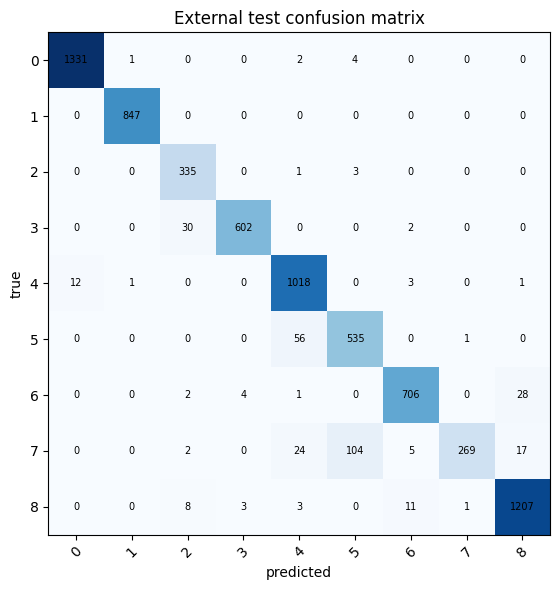

In [10]:
import os, torch, timm, numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset, Image as HFImage, ClassLabel
from torch.utils.data import DataLoader
from torchvision import transforms as T
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from google.colab import drive

DEVICE, REPO = "cuda", "chehablab/NCT-CRC-HE-100K"

# --- find the saved weights (Drive backup first, then local disk) ---
try:
    drive.mount("/content/drive")
except Exception as e:                      # mount can fail (auth popup closed, blocked cookies, timeout)
    print("Drive mount failed, falling back to local weights:", e)
WEIGHTS = "/content/drive/MyDrive/pathvoice/resnet18_finetuned.pt"
if not os.path.exists(WEIGHTS):
    WEIGHTS = "resnet18_finetuned.pt"
assert os.path.exists(WEIGHTS), "no weights found: the model needs retraining"
print("using weights:", WEIGHTS)

# --- external test set only (different patients) ---
test_full = load_dataset(REPO, split="test")
feats = test_full.features
IMG_COL = next(k for k, v in feats.items() if isinstance(v, HFImage))
LBL_COL = "label" if "label" in feats else next(
    k for k, v in feats.items()
    if isinstance(v, ClassLabel) or getattr(v, "dtype", "") in ("int64", "int32", "string"))
print("image column:", IMG_COL, "| label column:", LBL_COL)

lf = feats[LBL_COL]
if isinstance(lf, ClassLabel):
    CLASSES = list(lf.names); to_idx = int
elif getattr(lf, "dtype", "") == "string":
    CLASSES = sorted(set(test_full[LBL_COL])); _m = {c: i for i, c in enumerate(CLASSES)}
    to_idx = lambda v: _m[v]
else:
    _ids = sorted(set(int(v) for v in test_full[LBL_COL]))
    CLASSES = [str(i) for i in _ids]; to_idx = lambda v: _ids.index(int(v))
print("classes:", CLASSES)
assert len(CLASSES) == 9

# --- same preprocessing as training ---
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
eval_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(MEAN, STD)])

def make(ds, tf):
    def fn(batch):
        return {"x": [tf(im.convert("RGB")) for im in batch[IMG_COL]],
                "y": [to_idx(l) for l in batch[LBL_COL]]}
    return ds.with_transform(fn)

external_dl = DataLoader(make(test_full, eval_tf), batch_size=64, shuffle=False,
                         num_workers=min(4, os.cpu_count() or 2), pin_memory=True)

# --- load the trained model ---
model = timm.create_model("resnet18", pretrained=False, num_classes=len(CLASSES)).to(DEVICE)
model.load_state_dict(torch.load(WEIGHTS, map_location=DEVICE))
model.eval()

@torch.no_grad()
def get_logits(model, dl):
    model.eval(); L, Y = [], []
    for b in dl:
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(b["x"].to(DEVICE, non_blocking=True))
        L.append(out.float().cpu()); Y.append(b["y"])
    return torch.cat(L), torch.cat(Y)

# --- evaluate ---
lg_ext, y_ext = get_logits(model, external_dl)
pred, yt = lg_ext.argmax(1).numpy(), y_ext.numpy()
print(f"\nEXTERNAL TEST  images: {len(yt)}  acc: {(pred == yt).mean():.4f}  macro-F1: {f1_score(yt, pred, average='macro'):.4f}\n")
print(classification_report(yt, pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(yt, pred)
fig, ax = plt.subplots(figsize=(7, 6)); ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=45)
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("External test confusion matrix")
plt.tight_layout(); plt.show()

# Step 1: Baseline metrics (accuracy, macro-F1, ECE, tumor recall/precision, coverage vs accuracy) + Kather evaluation

Run after the cell that loads the trained model (the last cell above), so `model`, `external_dl`, `get_logits`, `eval_tf`, `make`, `CLASSES` exist.
Everything here is the **baseline** (`resnet18_finetuned.pt`); the logits are stored in `lg_base_*` so Step 2 can compare against them.

In [ ]:
!pip install -q tabulate   # needed for DataFrame.to_markdown
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from sklearn.metrics import f1_score

TUM_IDX = 8                       # CLASS_NAMES order in backend/app/classes.py: ADI BACK DEB LYM MUC MUS NORM STR TUM
THRESHOLDS = [0.50, 0.70, 0.80, 0.90, 0.95, 0.99]
UNCERTAIN_T = 0.70                # same cut-off the API uses

def ece_score(conf, correct, n_bins=15):
    """Expected calibration error, equal-width bins on top-1 confidence."""
    edges = np.linspace(0, 1, n_bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(e)

def summarize(logits, y, temperature=1.0):
    """All headline metrics for one set of logits. y uses the model's 0..8 indices."""
    probs = torch.softmax(logits / temperature, 1).numpy()
    y = np.asarray(y); pred = probs.argmax(1); conf = probs.max(1); correct = (pred == y)
    present = sorted(set(y.tolist()))            # Kather has no MUC/MUS, so macro-F1 only over classes present
    tp = int(((pred == TUM_IDX) & (y == TUM_IDX)).sum())
    n_true, n_pred = int((y == TUM_IDX).sum()), int((pred == TUM_IDX).sum())
    keep = conf >= UNCERTAIN_T
    return {
        "n": len(y),
        "accuracy": correct.mean(),
        "macro_F1": f1_score(y, pred, average="macro", labels=present),
        "ECE": ece_score(conf, correct),
        "tumor_recall": tp / n_true if n_true else float("nan"),
        "tumor_precision": tp / n_pred if n_pred else float("nan"),
        "mean_confidence": conf.mean(),
        f"coverage@{UNCERTAIN_T}": keep.mean(),
        f"accuracy@{UNCERTAIN_T}": correct[keep].mean() if keep.any() else float("nan"),
    }

def coverage_table(logits, y, temperature=1.0, thresholds=THRESHOLDS):
    probs = torch.softmax(logits / temperature, 1).numpy(); y = np.asarray(y)
    conf, correct = probs.max(1), probs.argmax(1) == y
    rows = []
    for t in thresholds:
        m = conf >= t
        rows.append({"threshold": t, "coverage": m.mean(),
                     "accuracy_on_kept": correct[m].mean() if m.any() else float("nan")})
    return pd.DataFrame(rows)

def coverage_curve(logits, y, temperature=1.0):
    probs = torch.softmax(logits / temperature, 1).numpy(); y = np.asarray(y)
    conf, correct = probs.max(1), probs.argmax(1) == y
    order = np.argsort(-conf)                     # most confident first
    cov = np.arange(1, len(y) + 1) / len(y)
    acc = np.cumsum(correct[order]) / np.arange(1, len(y) + 1)
    return cov, acc

In [ ]:
# --- baseline on the external NCT-CRC test set (9 classes) ---
lg_base_ext, y_ext = get_logits(model, external_dl)
lg_base_ext, y_ext = lg_base_ext.cpu(), y_ext.cpu()

base_ext = summarize(lg_base_ext, y_ext.numpy())
print("EXTERNAL (NCT-CRC test)")
print(pd.Series(base_ext).to_string(float_format=lambda v: f"{v:.4f}"))
print()
print(coverage_table(lg_base_ext, y_ext.numpy()).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

## Kather evaluation (domain shift)

`dpdl-benchmark/colorectal_histology` (Kather 2016, 8 classes, 150x150). Same label mapping as `backend/tests/test_hf_smoke.py`:
tumor→TUM, stroma→STR, lympho→LYM, debris→DEB, mucosa→NORM, adipose→ADI, empty→BACK. The `complex` class has no equivalent in our 9 classes, so it is dropped from scoring.
The model has no MUC or MUS examples here, so macro-F1 is over the 7 classes that are present; tumor precision counts every image the model calls TUM.

In [ ]:
from collections import Counter
from datasets import load_dataset, Image as HFImage
from torch.utils.data import DataLoader

kather = load_dataset("dpdl-benchmark/colorectal_histology", split="train")
k_feats = kather.features
K_IMG = next(k for k, v in k_feats.items() if isinstance(v, HFImage))
print("label feature:", k_feats["label"])          # plain int column, no names attached
print("rows:", len(kather))

# This dataset ships labels as bare ints 0..7. Order as verified in backend/tests/test_hf_smoke.py
# (checked by eye on sample images): 0 tumor, 1 stroma, 2 complex, 3 lympho, 4 debris, 5 mucosa, 6 adipose, 7 empty.
# hf label -> our model index. "complex" (2) has no equivalent and is dropped.
K_MAP = {0: 8, 1: 7, 3: 3, 4: 2, 5: 6, 6: 0, 7: 1}
print("hf label counts:", dict(sorted(Counter(kather["label"]).items())))
assert set(kather["label"]) <= set(range(8)), "unexpected label values"

kather = kather.filter(lambda l: l in K_MAP, input_columns="label")
print("scored rows (complex dropped):", len(kather))

def k_fn(batch):
    return {"x": [eval_tf(im.convert("RGB")) for im in batch[K_IMG]],
            "y": [K_MAP[l] for l in batch["label"]]}
kather_dl = DataLoader(kather.with_transform(k_fn), batch_size=64, shuffle=False,
                       num_workers=min(4, os.cpu_count() or 2), pin_memory=True)

lg_base_kat, y_kat = get_logits(model, kather_dl)
lg_base_kat, y_kat = lg_base_kat.cpu(), y_kat.cpu()

base_kat = summarize(lg_base_kat, y_kat.numpy())
print("\nKATHER (7 mapped classes)")
print(pd.Series(base_kat).to_string(float_format=lambda v: f"{v:.4f}"))
print()
print(coverage_table(lg_base_kat, y_kat.numpy()).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

In [ ]:
# --- baseline table (this is the one to commit) ---
baseline_df = pd.DataFrame({"NCT-CRC external": base_ext, "Kather (7 classes)": base_kat})
display(baseline_df.style.format("{:.4f}", subset=pd.IndexSlice[[i for i in baseline_df.index if i != "n"], :]).format("{:.0f}", subset=pd.IndexSlice[["n"], :]))

baseline_df.to_csv("baseline_metrics.csv")
with open("baseline_metrics.md", "w") as f:
    f.write(baseline_df.round(4).to_markdown())
print("wrote baseline_metrics.csv and baseline_metrics.md")

# coverage vs accuracy
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, lg, yy in [("NCT-CRC external", lg_base_ext, y_ext.numpy()), ("Kather", lg_base_kat, y_kat.numpy())]:
    cov, acc = coverage_curve(lg, yy)
    axes[0].plot(cov, acc, label=name)
axes[0].set_xlabel("coverage (fraction of images answered)"); axes[0].set_ylabel("accuracy on answered")
axes[0].set_title("Coverage vs accuracy (baseline)"); axes[0].legend(); axes[0].grid(alpha=.3)

# reliability diagram, external
probs = torch.softmax(lg_base_ext, 1).numpy(); conf = probs.max(1); corr = probs.argmax(1) == y_ext.numpy()
edges = np.linspace(0, 1, 11)
xs, ys = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (conf > lo) & (conf <= hi)
    if m.any(): xs.append(conf[m].mean()); ys.append(corr[m].mean())
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].plot(xs, ys, "o-")
axes[1].set_xlabel("mean confidence"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Reliability, external (baseline)")
axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("baseline_coverage_reliability.png", dpi=150); plt.show()

**Questions for the PathAI contact**: not in this notebook. Send them separately (I don't have the wording or the contact).

# Step 2: Retrain with colour augmentation + label smoothing; temperature scaling on half the external set

Needs Step 1 to have run (uses `lg_base_ext`, `y_ext`, `lg_base_kat`, `y_kat`, `summarize`) and the data-pipeline cells (`train_ds`, `calib_ds`, `make`, `eval_tf`, `MEAN`, `STD`).
The baseline weights are not touched: the new model is a separate `model_v2`, saved as `resnet18_finetuned_v2.pt`.
Changes vs the baseline recipe: `ColorJitter` (stain/colour variation) and `label_smoothing=0.1`. Everything else (5 epochs, OneCycle, AdamW, lr 5e-4) is identical so the comparison is clean.

In [ ]:
import time, timm, shutil, torch.nn.functional as F
from torchvision import transforms as T
from torch.utils.data import DataLoader

LABEL_SMOOTHING = 0.1
EPOCHS_V2, MAX_LR_V2 = 5, 5e-4
NW = min(4, os.cpu_count() or 2)

train_tf_v2 = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomApply([T.RandomRotation((90, 90))], p=0.5),
    T.RandomApply([T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05)], p=0.8),
    T.ToTensor(), T.Normalize(MEAN, STD)])

train_dl_v2 = DataLoader(make(train_ds, train_tf_v2), batch_size=64, shuffle=True, num_workers=NW,
                         pin_memory=True, persistent_workers=True)
calib_dl_v2 = DataLoader(make(calib_ds, eval_tf), batch_size=64, shuffle=False, num_workers=NW,
                         pin_memory=True, persistent_workers=True)

model_v2 = timm.create_model("resnet18", pretrained=True, num_classes=len(CLASSES)).to(DEVICE)
opt2 = torch.optim.AdamW(model_v2.parameters(), lr=MAX_LR_V2, weight_decay=1e-4)
sched2 = torch.optim.lr_scheduler.OneCycleLR(opt2, max_lr=MAX_LR_V2, total_steps=EPOCHS_V2 * len(train_dl_v2))
scaler2 = torch.amp.GradScaler("cuda")

for ep in range(EPOCHS_V2):
    model_v2.train(); t0 = time.time(); run_loss = 0.0
    for b in train_dl_v2:
        x, y = b["x"].to(DEVICE, non_blocking=True), b["y"].to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = F.cross_entropy(model_v2(x), y, label_smoothing=LABEL_SMOOTHING)
        opt2.zero_grad(set_to_none=True)
        scaler2.scale(loss).backward()
        scaler2.step(opt2); scaler2.update(); sched2.step()
        run_loss += loss.item()
    lg, yy = get_logits(model_v2, calib_dl_v2)
    print(f"epoch {ep+1}/{EPOCHS_V2}  loss {run_loss/len(train_dl_v2):.3f}  "
          f"calib acc {(lg.argmax(1) == yy).float().mean().item():.3f}  ({time.time()-t0:.0f}s)")

torch.save(model_v2.state_dict(), "resnet18_finetuned_v2.pt")
if os.path.isdir("/content/drive/MyDrive/pathvoice"):          # same Drive backup folder as the baseline
    shutil.copy("resnet18_finetuned_v2.pt", "/content/drive/MyDrive/pathvoice/resnet18_finetuned_v2.pt")
print("saved resnet18_finetuned_v2.pt")

In [ ]:
# --- logits for the retrained model on both evaluation sets ---
lg_v2_ext, y_ext2 = get_logits(model_v2, external_dl)
lg_v2_kat, y_kat2 = get_logits(model_v2, kather_dl)
lg_v2_ext, lg_v2_kat = lg_v2_ext.cpu(), lg_v2_kat.cpu()
assert torch.equal(y_ext2.cpu(), y_ext) and torch.equal(y_kat2.cpu(), y_kat)   # same order as the baseline run

# --- temperature scaling: fit on half A of the external set, test on half B ---
from sklearn.model_selection import train_test_split
idx_A, idx_B = train_test_split(np.arange(len(y_ext)), test_size=0.5, stratify=y_ext.numpy(), random_state=42)
idx_A, idx_B = torch.as_tensor(idx_A), torch.as_tensor(idx_B)
print("external half A (fit T):", len(idx_A), "| half B (test):", len(idx_B))

def fit_temperature(logits, y):
    """Single scalar T minimising NLL (plain cross-entropy, no smoothing)."""
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)
    def closure():
        opt.zero_grad(); loss = F.cross_entropy(logits / log_t.exp(), y); loss.backward(); return loss
    opt.step(closure)
    return log_t.exp().item()

T_base = fit_temperature(lg_base_ext[idx_A], y_ext[idx_A])
T_v2   = fit_temperature(lg_v2_ext[idx_A],   y_ext[idx_A])
print(f"fitted temperature  baseline: {T_base:.3f}   v2: {T_v2:.3f}")

In [ ]:
# --- before / after, all on the held-out external half B ---
yB = y_ext[idx_B].numpy()
cols_B = {
    "baseline (before)":       summarize(lg_base_ext[idx_B], yB),
    "baseline + temp scaling": summarize(lg_base_ext[idx_B], yB, temperature=T_base),
    "v2 aug+smoothing":        summarize(lg_v2_ext[idx_B],   yB),
    "v2 + temp scaling (after)": summarize(lg_v2_ext[idx_B], yB, temperature=T_v2),
}
table_ext = pd.DataFrame(cols_B)
print("NCT-CRC external, half B (never used to fit T)")
display(table_ext.style.format("{:.4f}", subset=pd.IndexSlice[[i for i in table_ext.index if i != "n"], :]).format("{:.0f}", subset=pd.IndexSlice[["n"], :]))

# --- same four configurations on Kather (T from external half A, so this is a cross-domain check) ---
yK = y_kat.numpy()
cols_K = {
    "baseline (before)":       summarize(lg_base_kat, yK),
    "baseline + temp scaling": summarize(lg_base_kat, yK, temperature=T_base),
    "v2 aug+smoothing":        summarize(lg_v2_kat,   yK),
    "v2 + temp scaling (after)": summarize(lg_v2_kat, yK, temperature=T_v2),
}
table_kat = pd.DataFrame(cols_K)
print("Kather (7 classes), temperature fitted on external half A")
display(table_kat.style.format("{:.4f}", subset=pd.IndexSlice[[i for i in table_kat.index if i != "n"], :]).format("{:.0f}", subset=pd.IndexSlice[["n"], :]))

table_ext.to_csv("before_after_external_halfB.csv"); table_kat.to_csv("before_after_kather.csv")
with open("before_after.md", "w") as f:
    f.write("## NCT-CRC external, half B\n\n" + table_ext.round(4).to_markdown() +
            "\n\n## Kather (7 classes)\n\n" + table_kat.round(4).to_markdown() + "\n")

# coverage vs accuracy, before vs after, on external half B
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, lg, t in [("baseline (before)", lg_base_ext[idx_B], 1.0), ("v2 + temp scaling (after)", lg_v2_ext[idx_B], T_v2)]:
    cov, acc = coverage_curve(lg, yB, t); axes[0].plot(cov, acc, label=name)
axes[0].set_xlabel("coverage"); axes[0].set_ylabel("accuracy on answered")
axes[0].set_title("Coverage vs accuracy, external half B"); axes[0].legend(); axes[0].grid(alpha=.3)
for name, lg, t in [("baseline (before)", lg_base_kat, 1.0), ("v2 + temp scaling (after)", lg_v2_kat, T_v2)]:
    cov, acc = coverage_curve(lg, yK, t); axes[1].plot(cov, acc, label=name)
axes[1].set_xlabel("coverage"); axes[1].set_ylabel("accuracy on answered")
axes[1].set_title("Coverage vs accuracy, Kather"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("before_after_coverage.png", dpi=150); plt.show()